<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9610.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['figure.figsize'] = (10.0, 5.0)

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Завдання 1. Затухання градієнта

> Перевірити на практиці твердження про затухання градієнта. У документації PyTorch можна знайти такі функції активації: ELU, Hardtanh, LeakyReLU, LogSigmoid, PReLU, ReLU, ReLU6, RReLU, SELU, CELU, Sigmoid, Softplus, Softshrink, Softsign, Tanh, Tanhshrink, Hardshrink.
>
> Вам належить знайти активацію, яка призводить до найменшого загасання градієнта. Для перевірки ми сконструюємо SimpleNet, яка буде мати всередині 3 fc-шару, по 1 нейрону в кожному без bias. Ваги цих нейронів ми ініціалізуємо одиницями. На вхід в цю мережу будемо подавати числа з нормального розподілу. Зробимо 200 запусків (NUMBER_OF_EXPERIMENTS) для чесного порівняння і порахуємо середнє значення градієнта в першому шарі.
>
> Знайдіть таку функцію, яка буде давати максимальні значення градієнта в першому шарі. Всі функції активації потрібно форматувати з аргументами за замовчуванням (порожніми дужками).

In [ ]:
seed = 0
np.random.seed(seed)
torch.manual_seed(seed)

NUMBER_OF_EXPERIMENTS = 200

class SimpleNet(torch.nn.Module):
    def __init__(self, activation):
        super().__init__()
        self.activation = activation
        self.fc1 = torch.nn.Linear(1, 1, bias=False)
        self.fc1.weight.data.fill_(1.)
        self.fc2 = torch.nn.Linear(1, 1, bias=False)
        self.fc2.weight.data.fill_(1.)
        self.fc3 = torch.nn.Linear(1, 1, bias=False)
        self.fc3.weight.data.fill_(1.)

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.activation(self.fc3(x))
        return x

    def get_fc1_grad_abs_value(self):
        return torch.abs(self.fc1.weight.grad)

def get_fc1_grad_abs_value(net, x):
    output = net.forward(x)
    output.backward()
    fc1_grad = net.get_fc1_grad_abs_value().item()
    net.zero_grad()
    return fc1_grad

activation_classes = {
    'ELU': torch.nn.ELU, 'Hardtanh': torch.nn.Hardtanh, 'LeakyReLU': torch.nn.LeakyReLU,
    'LogSigmoid': torch.nn.LogSigmoid, 'PReLU': torch.nn.PReLU, 'ReLU': torch.nn.ReLU,
    'ReLU6': torch.nn.ReLU6, 'RReLU': torch.nn.RReLU, 'SELU': torch.nn.SELU, 'CELU': torch.nn.CELU,
    'Sigmoid': torch.nn.Sigmoid, 'Softplus': torch.nn.Softplus, 'Softshrink': torch.nn.Softshrink,
    'Softsign': torch.nn.Softsign, 'Tanh': torch.nn.Tanh, 'Tanhshrink': torch.nn.Tanhshrink,
    'Hardshrink': torch.nn.Hardshrink,
}

def mean_first_layer_grad(activation_class, seed):
    torch.manual_seed(seed)
    net = SimpleNet(activation=activation_class())
    fc1_grads = []
    for x in torch.randn((NUMBER_OF_EXPERIMENTS, 1)):
        fc1_grads.append(get_fc1_grad_abs_value(net, x))
    return np.mean(fc1_grads)

results = {name: mean_first_layer_grad(cls, seed) for name, cls in activation_classes.items()}
gradient_table = pd.Series(results, name='середній |градієнт| першого шару').sort_values(ascending=False)
print(gradient_table.round(4).to_string())
print()
print("Найбільший градієнт:", gradient_table.index[0], round(gradient_table.iloc[0], 4))

Hardshrink    0.6755
SELU          0.6494
CELU          0.5131
ELU           0.5131
PReLU         0.4703
RReLU         0.4685
LeakyReLU     0.4653
ReLU          0.4653
ReLU6         0.4653
Hardtanh      0.3072
Softplus      0.2802
Softshrink    0.2211
LogSigmoid    0.2129
Tanh          0.1690
Softsign      0.0651
Tanhshrink    0.0253
Sigmoid       0.0072

Найбільший градієнт: Hardshrink 0.6755


Якщо градієнт майже не доходить до першого шару, його значення близьке до нуля: це і є затухання. Для кожної активації мережа створюється з однаковими вагами, і на 200 нормально розподілених входів вимірюється середнє абсолютне значення градієнта ваги першого шару.

In [ ]:
seeds_check = (0, 1, 2, 3, 4)
rows = {}
for name, cls in activation_classes.items():
    values = [mean_first_layer_grad(cls, s) for s in seeds_check]
    rows[name] = {'середнє за 5 seed': np.mean(values), 'мін': np.min(values), 'макс': np.max(values)}

stability_table = pd.DataFrame(rows).T.sort_values('середнє за 5 seed', ascending=False)
print(stability_table.round(4).to_string())

            середнє за 5 seed     мін    макс
Hardshrink             0.7090  0.6408  0.7768
SELU                   0.6122  0.5393  0.6494
CELU                   0.4729  0.4030  0.5131
ELU                    0.4729  0.4030  0.5131
PReLU                  0.4225  0.3475  0.4703
RReLU                  0.4211  0.3463  0.4685
LeakyReLU              0.4165  0.3403  0.4653
ReLU                   0.4165  0.3403  0.4653
ReLU6                  0.4165  0.3403  0.4653
Hardtanh               0.3111  0.2891  0.3367
Softshrink             0.2727  0.2164  0.3367
Softplus               0.2668  0.2259  0.2922
LogSigmoid             0.2432  0.2018  0.2855
Tanh                   0.1663  0.1631  0.1693
Softsign               0.0645  0.0639  0.0654
Tanhshrink             0.0301  0.0184  0.0433
Sigmoid                0.0072  0.0069  0.0075


**Результат.** Найбільший градієнт у першому шарі дає Hardshrink (середнє 0.676 за 200 запусків і 0.709 за п'ять різних seed), за ним SELU (0.649 і 0.612) та CELU і ELU (по 0.513 і 0.473). Група ReLU, LeakyReLU і ReLU6 дає 0.465 (0.417 за п'ять seed), PReLU і RReLU близькі до неї. Найменший градієнт у Sigmoid (0.007), далі Tanhshrink (0.025) і Softsign (0.065), а Tanh дає 0.169. Ці значення пояснюють затухання градієнта: похідна сигмоїди не перевищує 0.25, тому після проходу через три шари градієнт зменшується приблизно в 60 разів і більше, а Tanh та Softsign мають похідну менше одиниці скрізь, крім нуля. Функції, чия похідна дорівнює одиниці на великій частині області (ReLU та його варіанти, ELU, SELU, Hardshrink), затухання майже не мають. Для ELU і CELU результати збігаються, бо при значенні параметра за замовчуванням це одна й та сама функція. Те саме стосується ReLU, LeakyReLU і ReLU6 на цих входах: нормально розподілені числа рідко виходять за межі 6, а від'ємна ділянка LeakyReLU тут майже не вносить внеску в градієнт. Hardshrink виграє в цьому тесті, бо на значеннях за модулем більших за 0.5 її похідна дорівнює 1, а на менших дорівнює нулю, тож середнє значення вище, ніж у ReLU, де градієнт зникає на всій від'ємній півосі. Це лише вимірювання затухання, а не доказ, що Hardshrink найкраща для навчання.

# Завдання 2. LeNet5 і пакетна нормалізація

> Натренуйте модель LeNet5 надану в теоретичному описі. Проведіть наступні експерименти:
>
> a. Зробіть кілька експериментів з параметрами, що надані у теоретичному описі. Проаналізуйте отриманий результат. При яких параметрах отримуємо найкращу якість? Які покращення дали результат? Спробуйте пояснити.
>
> b. Зробіть аналогічні дії на датасеті CIFAR10 (можете спробувати натренувати CIFAR100 – розширена версія цього набору даних, має 100 класів). Порівняйте результати із покращеннями, що дали найбільший внесок.
>
> c. Спробуйте додати фільтрів і подивитися – а якщо ми з зображення будемо отримувати більше інформації, яка буде точність моделі?
>
> d. Крім того, зробіть згортки, що виходять за розмір зображення, щоб цей розмір не мінявся до і після згортки (тобто паддінг = 1).
>
> e. Застосуйте Батч-нормалізацію до вихідного зображення (в самому началі мережі) – таку Батч-нормалізацію можна трактувати як нормування по яскравості і контрасту початкового зображення.
>
> f. Проаналізуйте результат та знайдіть оптимальну кількість епох для навчання (точку зупинки, щоб уникнути перенавчання), аналізуючи графіки втрат.
>
> g. Спробуйте додати ще такі шари як DropOut (nn.Dropout(), nn.Dropout2d (тут вказується частка нейронів, що буде вимкнена), перед згорткою (після нормалізації) або повнозв'язним шаром).
>
> h. Спробуйте додати l2-регуляризацію. У PyTorch вона активується за допомогою параметра weight_decay в оптимізаторі (для всіх шарів одразу в автоматичному режимі). Значення зазвичай вибирають з [1e-3, 1e-4, 1e-5]. Значення 1e-2 ставити не варто, тому що мережа не зможе вчитися, а 1e-6 швидше за все просто не вплине на навчання (але краще перевірити це твердження самостійно).

## Дані MNIST і CIFAR10

In [ ]:
MNIST_train = torchvision.datasets.MNIST('./', download=True, train=True)
MNIST_test = torchvision.datasets.MNIST('./', download=True, train=False)

X_mnist = MNIST_train.data.unsqueeze(1).float() / 255.
y_mnist = MNIST_train.targets
X_mnist_test = MNIST_test.data.unsqueeze(1).float() / 255.
y_mnist_test = MNIST_test.targets

mnist_mean, mnist_std = X_mnist.mean(), X_mnist.std()
X_mnist = (X_mnist - mnist_mean) / mnist_std
X_mnist_test = (X_mnist_test - mnist_mean) / mnist_std

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_mnist), generator=generator)
mv, mt = permutation[:10000], permutation[10000:]

Xm_val, ym_val = X_mnist[mv].to(device), y_mnist[mv].to(device)
Xm_tr, ym_tr = X_mnist[mt].to(device), y_mnist[mt].to(device)
Xm_test, ym_test = X_mnist_test.to(device), y_mnist_test.to(device)

print("MNIST:", Xm_tr.shape, Xm_val.shape, Xm_test.shape)

MNIST: torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

X_cifar = torch.from_numpy(CIFAR_train.data).float().div(255.).permute(0, 3, 1, 2)
y_cifar = torch.tensor(CIFAR_train.targets)
X_cifar_test = torch.from_numpy(CIFAR_test.data).float().div(255.).permute(0, 3, 1, 2)
y_cifar_test = torch.tensor(CIFAR_test.targets)

channel_mean = X_cifar.mean(dim=(0, 2, 3), keepdim=True)
channel_std = X_cifar.std(dim=(0, 2, 3), keepdim=True)

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_cifar), generator=generator)
cv, ct = permutation[:5000], permutation[5000:]

def to_device(tensor_cifar, tensor_labels, idx=None, normalize=True):
    if idx is not None:
        tensor_cifar, tensor_labels = tensor_cifar[idx], tensor_labels[idx]
    if normalize:
        tensor_cifar = (tensor_cifar - channel_mean) / channel_std
    return tensor_cifar.to(device), tensor_labels.to(device)

Xc_tr, yc_tr = to_device(X_cifar, y_cifar, ct)
Xc_val, yc_val = to_device(X_cifar, y_cifar, cv)
Xc_test, yc_test = to_device(X_cifar_test, y_cifar_test)

Xr_tr, yr_tr = to_device(X_cifar, y_cifar, ct, normalize=False)
Xr_val, yr_val = to_device(X_cifar, y_cifar, cv, normalize=False)
Xr_test, yr_test = to_device(X_cifar_test, y_cifar_test, normalize=False)

print("CIFAR10 (нормовані):", Xc_tr.shape, Xc_val.shape, Xc_test.shape)
print("CIFAR10 (лише /255):", Xr_tr.shape, Xr_val.shape, Xr_test.shape)

CIFAR10 (нормовані): torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
CIFAR10 (лише /255): torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


Для MNIST та для першої частини експериментів із CIFAR10 пікселі нормуються за середнім і стандартним відхиленням. Для останньої частини (завдання d–h) готується також варіант, де значення лише ділені на 255, бо там нормування вхідного зображення виконує сам шар пакетної нормалізації. У обох наборах частина тренувальних даних (10 000 для MNIST і 5000 для CIFAR10) відводиться на валідацію.

## Модель LeNet5 з параметрами

In [ ]:
class LeNet5(torch.nn.Module):
    def __init__(self, activation='tanh', pooling='avg', conv_size=5, use_batch_norm=False,
                 in_channels=1, input_padding=2, width=1):
        super(LeNet5, self).__init__()

        self.conv_size = conv_size
        self.use_batch_norm = use_batch_norm

        if activation == 'tanh':
            activation_function = torch.nn.Tanh()
        elif activation == 'relu':
            activation_function = torch.nn.ReLU()
        else:
            raise NotImplementedError

        if pooling == 'avg':
            pooling_layer = torch.nn.AvgPool2d(kernel_size=2, stride=2)
        elif pooling == 'max':
            pooling_layer = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        else:
            raise NotImplementedError

        c1, c2 = 6 * width, 16 * width

        if conv_size == 5:
            self.conv1 = torch.nn.Conv2d(
                in_channels=in_channels, out_channels=c1, kernel_size=5, padding=input_padding)
        elif conv_size == 3:
            self.conv1_1 = torch.nn.Conv2d(
                in_channels=in_channels, out_channels=c1, kernel_size=3, padding=input_padding // 2)
            self.conv1_2 = torch.nn.Conv2d(
                in_channels=c1, out_channels=c1, kernel_size=3, padding=input_padding // 2)
        else:
            raise NotImplementedError

        self.act1 = activation_function
        self.bn1 = torch.nn.BatchNorm2d(num_features=c1)
        self.pool1 = pooling_layer

        if conv_size == 5:
            self.conv2 = torch.nn.Conv2d(
                in_channels=c1, out_channels=c2, kernel_size=5, padding=0)
        elif conv_size == 3:
            self.conv2_1 = torch.nn.Conv2d(
                in_channels=c1, out_channels=c2, kernel_size=3, padding=0)
            self.conv2_2 = torch.nn.Conv2d(
                in_channels=c2, out_channels=c2, kernel_size=3, padding=0)
        else:
            raise NotImplementedError

        self.act2 = activation_function
        self.bn2 = torch.nn.BatchNorm2d(num_features=c2)
        self.pool2 = pooling_layer

        self.fc1 = torch.nn.Linear(5 * 5 * c2, 120)
        self.act3 = activation_function

        self.fc2 = torch.nn.Linear(120, 84)
        self.act4 = activation_function

        self.fc3 = torch.nn.Linear(84, 10)

    def forward(self, x):
        if self.conv_size == 5:
            x = self.conv1(x)
        elif self.conv_size == 3:
            x = self.conv1_2(self.conv1_1(x))
        x = self.act1(x)
        if self.use_batch_norm:
            x = self.bn1(x)
        x = self.pool1(x)

        if self.conv_size == 5:
            x = self.conv2(x)
        elif self.conv_size == 3:
            x = self.conv2_2(self.conv2_1(x))
        x = self.act2(x)
        if self.use_batch_norm:
            x = self.bn2(x)
        x = self.pool2(x)

        x = x.view(x.size(0), x.size(1) * x.size(2) * x.size(3))
        x = self.fc1(x)
        x = self.act3(x)
        x = self.fc2(x)
        x = self.act4(x)
        x = self.fc3(x)

        return x

for kwargs, shape in (({}, (2, 1, 28, 28)), ({'conv_size': 3}, (2, 1, 28, 28)),
                      ({'in_channels': 3, 'input_padding': 0}, (2, 3, 32, 32)),
                      ({'in_channels': 3, 'input_padding': 0, 'conv_size': 3}, (2, 3, 32, 32))):
    print(kwargs, '->', tuple(LeNet5(**kwargs)(torch.randn(*shape)).shape))

{} -> (2, 10)
{'conv_size': 3} -> (2, 10)
{'in_channels': 3, 'input_padding': 0} -> (2, 10)
{'in_channels': 3, 'input_padding': 0, 'conv_size': 3} -> (2, 10)


Мережа повторює код з теорії: активація (`tanh` або `relu`), пулінг (`avg` або `max`), розмір згортки (одна згортка 5 на 5 або дві послідовні 3 на 3) та вмикання пакетної нормалізації після активації. Додано лише кількість вхідних каналів, відступ першої згортки (2 для MNIST, 0 для CIFAR10, щоб після першого блоку був розмір 28 на 28) та множник кількості фільтрів `width` для завдання c.

## Функція навчання

In [ ]:
def evaluate(model, X, y, batch=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for start in range(0, len(X), batch):
            outputs = model(X[start:start + batch])
            total_loss += torch.nn.functional.cross_entropy(outputs, y[start:start + batch], reduction='sum').item()
            correct += (outputs.argmax(dim=1) == y[start:start + batch]).sum().item()
    return total_loss / len(X), correct / len(X)

def train(net, X_train, y_train, X_val, y_val, epochs, lr=1.0e-3, weight_decay=0.0, batch_size=100, seed=0):
    net = net.to(device)
    loss = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    order_generator = torch.Generator().manual_seed(seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}

    for epoch in range(epochs):
        start_time = time.perf_counter()
        order = torch.randperm(len(X_train), generator=order_generator).to(X_train.device)
        running_loss = 0.0

        for start_index in range(0, len(X_train), batch_size):
            optimizer.zero_grad()
            net.train()

            batch_indexes = order[start_index:start_index + batch_size]
            X_batch = X_train[batch_indexes]
            y_batch = y_train[batch_indexes]

            preds = net.forward(X_batch)
            loss_value = loss(preds, y_batch)
            loss_value.backward()

            optimizer.step()
            running_loss += loss_value.item() * len(batch_indexes)

        if device.type == 'cuda':
            torch.cuda.synchronize()
        history['epoch_time'].append(time.perf_counter() - start_time)

        net.eval()
        val_loss, val_acc = evaluate(net, X_val, y_val)
        history['train_loss'].append(running_loss / len(X_train))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    return history

def summarize(name, history, net, X_test, y_test):
    test_loss, test_acc = evaluate(net, X_test, y_test)
    return {
        'конфігурація': name,
        'best val accuracy': max(history['val_acc']),
        'епоха': int(np.argmax(history['val_acc'])) + 1,
        'min val loss': min(history['val_loss']),
        'test accuracy (остання епоха)': test_acc,
        'с / епоху': float(np.mean(history['epoch_time'])),
    }

Функція навчання така ж, як у теорії: батчі по 100, Adam зі швидкістю 1e-3, крос-ентропія. Перед навчанням на батчі мережа переводиться в режим `net.train()`, а перед перевіркою на валідації в режим `net.eval()`, щоб пакетна нормалізація використовувала запам'ятовані під час навчання середнє та стандартне відхилення і не змінювалась під час тестування.

# Завдання 2a. Експерименти з параметрами LeNet5 на MNIST

> a. Зробіть кілька експериментів з параметрами, що надані у теоретичному описі. Проаналізуйте отриманий результат. При яких параметрах отримуємо найкращу якість? Які покращення дали результат? Спробуйте пояснити.

In [ ]:
configs_a = {
    'tanh, conv 5, avg': dict(activation='tanh', conv_size=5),
    'relu, conv 5, avg': dict(activation='relu', conv_size=5),
    'relu, conv 3, avg': dict(activation='relu', conv_size=3),
    'relu, conv 3, max': dict(activation='relu', conv_size=3, pooling='max'),
    'relu, conv 3, max, BN': dict(activation='relu', conv_size=3, pooling='max', use_batch_norm=True),
}

EPOCHS_A = 8
rows_a, histories_a = [], {}

for name, cfg in configs_a.items():
    torch.manual_seed(0)
    net = LeNet5(**cfg).to(device)
    history = train(net, Xm_tr, ym_tr, Xm_val, ym_val, epochs=EPOCHS_A)
    histories_a[name] = history
    rows_a.append({**summarize(name, history, net, Xm_test, ym_test),
                   'параметрів': sum(p.numel() for p in net.parameters())})

table_a = pd.DataFrame(rows_a).set_index('конфігурація')
print(table_a.round(4).to_string())

                       best val accuracy  епоха  min val loss  test accuracy (остання епоха)  с / епоху  параметрів
конфігурація                                                                                                       
tanh, conv 5, avg                 0.9852      6        0.0514                         0.9849     5.8381       61750
relu, conv 5, avg                 0.9858      6        0.0475                         0.9888     5.6115       61750
relu, conv 3, avg                 0.9858      5        0.0523                         0.9870    11.0804       62768
relu, conv 3, max                 0.9863      5        0.0481                         0.9886    11.4351       62768
relu, conv 3, max, BN             0.9886      8        0.0421                         0.9908    11.5578       62768


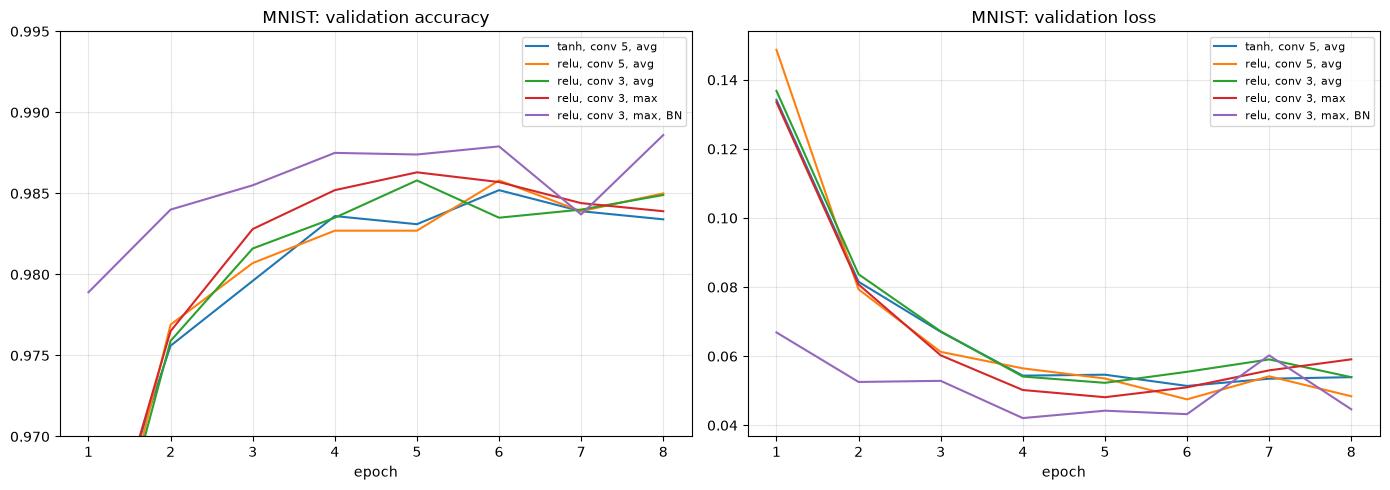

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories_a.items():
    axes[0].plot(range(1, EPOCHS_A + 1), history['val_acc'], label=name)
    axes[1].plot(range(1, EPOCHS_A + 1), history['val_loss'], label=name)
axes[0].set_title('MNIST: validation accuracy')
axes[1].set_title('MNIST: validation loss')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylim(0.97, 0.995)
plt.tight_layout()
plt.show()

**Результат (MNIST, 8 епох, один запуск кожної конфігурації).** Усі п'ять варіантів дають близькі результати: validation accuracy 0.9852–0.9886, test accuracy 0.9849–0.9908. Різниця між першими чотирма (tanh, ReLU, дві згортки 3 на 3, max pooling) становить соті частки відсотка, що лежить у межах випадкового розкиду між запусками. Помітно кращою виявилась лише конфігурація з пакетною нормалізацією: validation accuracy 0.9886 проти 0.9863 без неї (+0.2 п.п.) і test accuracy 0.9908 проти 0.9886. Також вона має найменшу втрату на валідації (0.0421).

Тобто на MNIST покращення дають небагато, бо задача проста, і навіть базова LeNet5 вже близька до стелі. Заміна Tanh на ReLU і average pooling на max pooling нічого істотного не змінила. Дві згортки 3 на 3 замість однієї 5 на 5 мають майже стільки ж параметрів (62 768 проти 61 750), але виконуються вдвічі довше (11 с проти 5.8 с на епоху), тому виграшу у швидкості немає. Одним запуском на конфігурацію висновки про малі різниці зробити не можна.

# Завдання 2b. Ті самі експерименти на CIFAR10

> b. Зробіть аналогічні дії на датасеті CIFAR10 (можете спробувати натренувати CIFAR100 – розширена версія цього набору даних, має 100 класів). Порівняйте результати із покращеннями, що дали найбільший внесок.

                       best val accuracy  епоха  min val loss  test accuracy (остання епоха)  с / епоху  параметрів
конфігурація                                                                                                       
tanh, conv 5, avg                 0.5670      8        1.2216                         0.5632     5.9131       62050
relu, conv 5, avg                 0.5770      8        1.1873                         0.5783     5.6999       62050
relu, conv 3, avg                 0.6108      8        1.1085                         0.6036    10.9128       62876
relu, conv 3, max                 0.6326      7        1.0354                         0.6395    10.9141       62876
relu, conv 3, max, BN             0.6762      7        0.9577                         0.6652    11.4279       62876


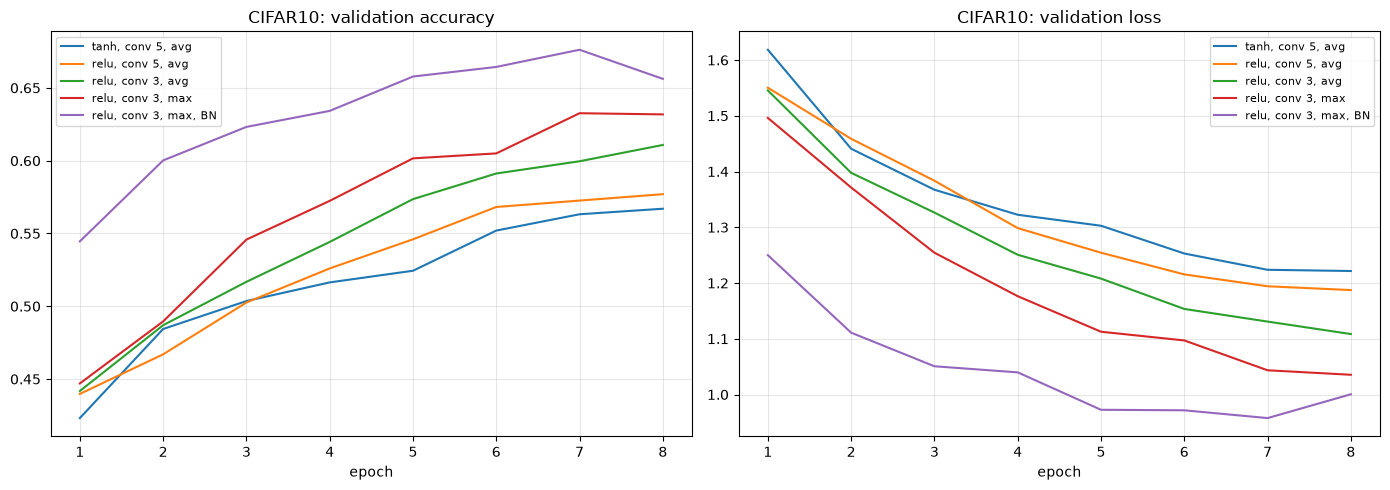

In [ ]:
EPOCHS_B = 8
rows_b, histories_b = [], {}

for name, cfg in configs_a.items():
    torch.manual_seed(0)
    net = LeNet5(in_channels=3, input_padding=0, **cfg).to(device)
    history = train(net, Xc_tr, yc_tr, Xc_val, yc_val, epochs=EPOCHS_B)
    histories_b[name] = history
    rows_b.append({**summarize(name, history, net, Xc_test, yc_test),
                   'параметрів': sum(p.numel() for p in net.parameters())})

table_b = pd.DataFrame(rows_b).set_index('конфігурація')
print(table_b.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories_b.items():
    axes[0].plot(range(1, EPOCHS_B + 1), history['val_acc'], label=name)
    axes[1].plot(range(1, EPOCHS_B + 1), history['val_loss'], label=name)
axes[0].set_title('CIFAR10: validation accuracy')
axes[1].set_title('CIFAR10: validation loss')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Результат (CIFAR10, 8 епох, один запуск кожної конфігурації).** Тут покращення видно чітко. Test accuracy зростає від 0.563 (tanh, згортка 5 на 5, average pooling) до 0.578 (ReLU), 0.604 (дві згортки 3 на 3), 0.640 (max pooling) і 0.665 (пакетна нормалізація). Validation loss зменшується з 1.222 до 0.958. Кожне з покращень дає внесок, а найбільший приріст дають заміна average pooling на max pooling (+3.6 п.п. на тесті) і пакетна нормалізація (+2.6 п.п.), далі дві згортки 3 на 3 (+2.5 п.п.), а ReLU замість Tanh (+1.5 п.п.) найменший.

Пояснення: ReLU не насичується, тому градієнти краще доходять до початкових шарів (це видно і в завданні 1). Дві згортки 3 на 3 мають те саме рецептивне поле, що й одна 5 на 5, але вносять додаткову нелінійність. Max pooling залишає найсильнішу реакцію фільтра, що корисно для складних зображень CIFAR10, а average pooling її розмиває. Пакетна нормалізація стабілізує розподіл активацій і прискорює навчання. На відміну від MNIST, на CIFAR10 є куди покращувати, тому ефект від кожної зміни помітний. Результати отримано одним запуском, тому різниці в 1–2 п.п. слід сприймати обережно.

# Завдання 2c. Більше фільтрів

> c. Спробуйте додати фільтрів і подивитися – а якщо ми з зображення будемо отримувати більше інформації, яка буде точність моделі?

In [ ]:
best_cfg_b = configs_a[table_b['best val accuracy'].idxmax()]
print("Базова конфігурація:", table_b['best val accuracy'].idxmax())

rows_c = []
for width in (1, 2, 4):
    torch.manual_seed(0)
    net = LeNet5(in_channels=3, input_padding=0, width=width, **best_cfg_b).to(device)
    history = train(net, Xc_tr, yc_tr, Xc_val, yc_val, epochs=EPOCHS_B)
    rows_c.append({**summarize(f'{6 * width} і {16 * width} фільтрів', history, net, Xc_test, yc_test),
                   'параметрів': sum(p.numel() for p in net.parameters())})

table_c = pd.DataFrame(rows_c).set_index('конфігурація')
print(table_c.round(4).to_string())

Базова конфігурація: relu, conv 3, max, BN


                  best val accuracy  епоха  min val loss  test accuracy (остання епоха)  с / епоху  параметрів
конфігурація                                                                                                  
6 і 16 фільтрів              0.6762      7        0.9577                         0.6652    11.3312       62876
12 і 32 фільтрів             0.7176      7        0.8372                         0.7188    15.9091      121602
24 і 64 фільтрів             0.7348      5        0.7724                         0.7392    25.9513      260006


**Результат.** Збільшення кількості фільтрів стабільно покращує точність: 6 і 16 фільтрів дають test accuracy 0.665, 12 і 32 фільтрів 0.719, 24 і 64 фільтрів 0.739. Validation loss зменшується з 0.958 до 0.772. Мережа отримує з зображення більше ознак, тому краще розрізняє класи. Ціна цього: кількість параметрів зростає з 62 876 до 260 006, а час епохи з 11 с до 26 с. Приріст від другого подвоєння (+2 п.п.) менший, ніж від першого (+5 п.п.), тобто віддача зменшується.

## Мережа із загальної структури (завдання d–h)

In [ ]:
class ConvNet(torch.nn.Module):
    def __init__(self, padding=1, input_bn=True, layer_bn=True, dropout=0.0, dropout2d=0.0):
        super(ConvNet, self).__init__()

        def block(c_in, c_out, pool):
            layers = [torch.nn.Conv2d(c_in, c_out, kernel_size=3, padding=padding), torch.nn.ReLU()]
            if layer_bn:
                layers.append(torch.nn.BatchNorm2d(c_out))
            if dropout2d > 0:
                layers.append(torch.nn.Dropout2d(dropout2d))
            if pool:
                layers.append(torch.nn.MaxPool2d(2))
            return layers

        layers = []
        if input_bn:
            layers.append(torch.nn.BatchNorm2d(3))
        layers += block(3, 16, True) + block(16, 32, True) + block(32, 64, False)
        self.features = torch.nn.Sequential(*layers)

        with torch.no_grad():
            flat_size = self.features(torch.zeros(2, 3, 32, 32)).flatten(1).shape[1]

        head = [torch.nn.Flatten()]
        if dropout > 0:
            head.append(torch.nn.Dropout(dropout))
        head += [torch.nn.Linear(flat_size, 256), torch.nn.Tanh()]
        if layer_bn:
            head.append(torch.nn.BatchNorm1d(256))
        if dropout > 0:
            head.append(torch.nn.Dropout(dropout))
        head += [torch.nn.Linear(256, 64), torch.nn.Tanh()]
        if layer_bn:
            head.append(torch.nn.BatchNorm1d(64))
        head.append(torch.nn.Linear(64, 10))
        self.classifier = torch.nn.Sequential(*head)
        self.flat_size = flat_size

    def forward(self, x):
        return self.classifier(self.features(x))

reference_net = ConvNet()
print(reference_net)
print("Розмір вектора перед першим повнозв'язним шаром:", reference_net.flat_size)
print("Кількість параметрів:", sum(p.numel() for p in reference_net.parameters()))

ConvNet(
  (features): Sequential(
    (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256

Мережа відповідає структурі із завдання: пакетна нормалізація на вході (3 канали), три згорткові блоки по 3 на 3 з 16, 32 і 64 каналами та `padding=1` (згортка + ReLU + пакетна нормалізація), два повнозв'язні шари на 256 та 64 нейрони з активацією Tanh і `BatchNorm1d`, і вихідний шар на 10 класів. У описі вказано, що перед першим повнозв'язним шаром розмір вектора дорівнює 8 × 8 × 64 = 4096, тому max pooling застосовується після перших двох блоків (32 → 16 → 8), а третій блок розмір не зменшує. Для CIFAR10 тут використовуються зображення зі значеннями лише від 0 до 1, бо нормування виконує шар пакетної нормалізації на вході.

# Завдання 2f. Оптимальна кількість епох

> f. Проаналізуйте результат та знайдіть оптимальну кількість епох для навчання (точку зупинки, щоб уникнути перенавчання), аналізуючи графіки втрат.

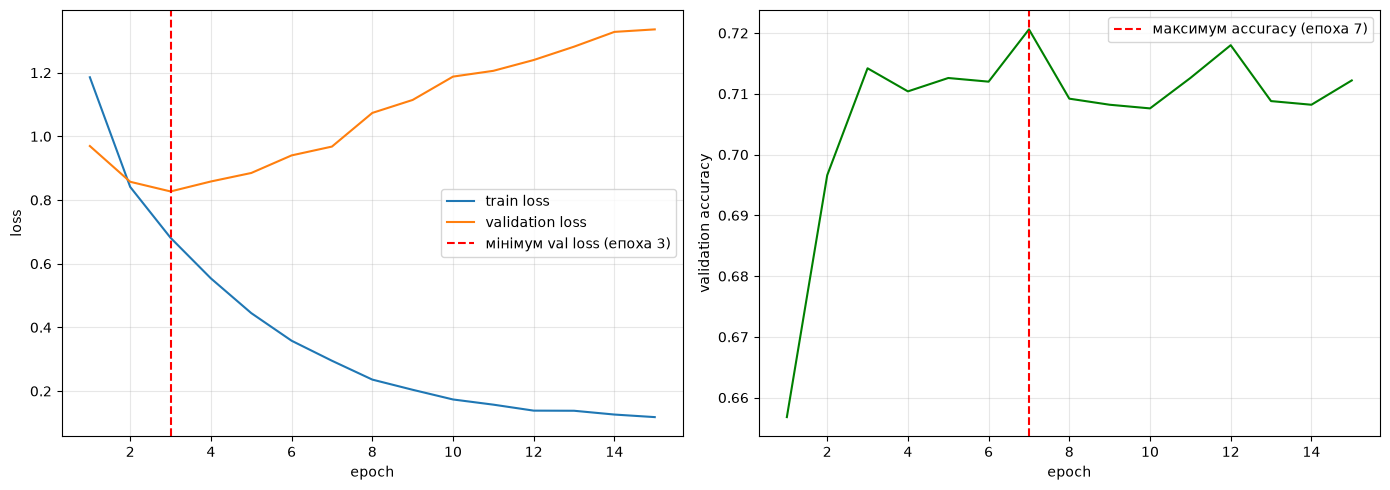

Мінімум validation loss: 0.827 на епосі 3
Максимум validation accuracy: 0.7206 на епосі 7
Train loss на епосі 15: 0.1181 | validation loss: 1.3361
Час епохи, с: 16.6


In [ ]:
EPOCHS_BASE = 15
EPOCHS_COMPARE = 6

torch.manual_seed(0)
base_net = ConvNet().to(device)
base_history = train(base_net, Xr_tr, yr_tr, Xr_val, yr_val, epochs=EPOCHS_BASE)

best_loss_epoch = int(np.argmin(base_history['val_loss'])) + 1
best_acc_epoch = int(np.argmax(base_history['val_acc'])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, EPOCHS_BASE + 1), base_history['train_loss'], label='train loss')
axes[0].plot(range(1, EPOCHS_BASE + 1), base_history['val_loss'], label='validation loss')
axes[0].axvline(best_loss_epoch, color='r', linestyle='--', label=f'мінімум val loss (епоха {best_loss_epoch})')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(range(1, EPOCHS_BASE + 1), base_history['val_acc'], color='g')
axes[1].axvline(best_acc_epoch, color='r', linestyle='--', label=f'максимум accuracy (епоха {best_acc_epoch})')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('validation accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Мінімум validation loss:", round(min(base_history['val_loss']), 4), "на епосі", best_loss_epoch)
print("Максимум validation accuracy:", round(max(base_history['val_acc']), 4), "на епосі", best_acc_epoch)
print("Train loss на епосі 15:", round(base_history['train_loss'][-1], 4), "| validation loss:", round(base_history['val_loss'][-1], 4))
print("Час епохи, с:", round(np.mean(base_history['epoch_time']), 1))

**Оптимальна кількість епох.** Для мережі із загальною структурою на CIFAR10 мінімум validation loss (0.827) припадає на 3-тю епоху, після чого вона зростає до 1.336 на 15-й епосі, а втрата на тренуванні продовжує падати до 0.118. Це явне перенавчання: мережа з 1.09 млн параметрів запам'ятовує тренувальні зображення. Validation accuracy при цьому досягає максимуму 0.7206 на 7-й епосі й далі не росте. Тому оптимальна кількість епох для цієї мережі без регуляризації становить 3–7: за мінімумом втрати 3 епохи, за максимумом точності 7. Для порівняльних експериментів нижче використано 6 епох. Для підсумкової мережі з регуляризацією (дивись нижче) мінімум втрати змістився на 12-ту епоху, тобто регуляризація дозволяє навчати довше без перенавчання.

# Завдання 2d. Padding 1 проти padding 0

> d. Крім того, зробіть згортки, що виходять за розмір зображення, щоб цей розмір не мінявся до і після згортки (тобто паддінг = 1).

In [ ]:
def compare_variants(variants, epochs=EPOCHS_COMPARE):
    rows = []
    for name, kwargs in variants.items():
        wd = kwargs.pop('weight_decay', 0.0)
        torch.manual_seed(0)
        net = ConvNet(**kwargs).to(device)
        history = train(net, Xr_tr, yr_tr, Xr_val, yr_val, epochs=epochs, weight_decay=wd)
        test_loss, test_acc = evaluate(net, Xr_test, yr_test)
        rows.append({'варіант': name,
                     'best val accuracy': max(history['val_acc']),
                     'val loss (остання)': history['val_loss'][-1],
                     'train loss (остання)': history['train_loss'][-1],
                     'test accuracy': test_acc})
    return pd.DataFrame(rows).set_index('варіант')

base_row = {'варіант': 'padding = 1 (базова)',
            'best val accuracy': max(base_history['val_acc'][:EPOCHS_COMPARE]),
            'val loss (остання)': base_history['val_loss'][EPOCHS_COMPARE - 1],
            'train loss (остання)': base_history['train_loss'][EPOCHS_COMPARE - 1]}

table_d = compare_variants({'padding = 0': dict(padding=0)})
print("Базова мережа (перші", EPOCHS_COMPARE, "епох історії):")
print({k: round(v, 4) if isinstance(v, float) else v for k, v in base_row.items()})
print()
print(table_d.round(4).to_string())

Базова мережа (перші 6 епох історії):
{'варіант': 'padding = 1 (базова)', 'best val accuracy': 0.7142, 'val loss (остання)': 0.9402, 'train loss (остання)': 0.358}

             best val accuracy  val loss (остання)  train loss (остання)  test accuracy
варіант                                                                                
padding = 0             0.6994              0.9239                0.5007          0.704


**Результат.** Базова мережа з `padding=1` за 6 епох має best validation accuracy 0.7142, а з `padding=0` 0.6994 (test accuracy 0.704). Згортки з відступом краще, приблизно на 1.5 п.п. на валідації. Причина в тому, що з `padding=1` розмір зображення не зменшується після кожної згортки, тому крайові пікселі не втрачаються, тобто мережа зберігає більше інформації. Нулі за межами зображення також дають мережі сигнал про розташування згортки біля краю. Різниця невелика і отримана одним запуском.

# Завдання 2e. Пакетна нормалізація

> e. Застосуйте Батч-нормалізацію до вихідного зображення (в самому началі мережі) – таку Батч-нормалізацію можна трактувати як нормування по яскравості і контрасту початкового зображення.

In [ ]:
table_e = compare_variants({
    'без BN на вході': dict(input_bn=False),
    'без жодної BN': dict(input_bn=False, layer_bn=False),
})
print("Базова (BN на вході й у шарах):", {k: round(v, 4) if isinstance(v, float) else v for k, v in base_row.items() if k != 'варіант'})
print()
print(table_e.round(4).to_string())

Базова (BN на вході й у шарах): {'best val accuracy': 0.7142, 'val loss (остання)': 0.9402, 'train loss (остання)': 0.358}

                 best val accuracy  val loss (остання)  train loss (остання)  test accuracy
варіант                                                                                    
без BN на вході             0.6864              1.0213                0.4235         0.6909
без жодної BN               0.6928              0.8873                0.7217         0.6969


**Результат.** Пакетна нормалізація покращує результат. Базова мережа (нормалізація на вході й після кожного шару) має best validation accuracy 0.7142. Без нормалізації на вході вона зменшується до 0.6864 (test 0.691), без жодної пакетної нормалізації до 0.6928 (test 0.697). Нормалізація входу працює як нормування за яскравістю та контрастом і дає приблизно +2.8 п.п. на валідації. Також нормалізація прискорює зменшення втрати на тренуванні: після 6 епох train loss дорівнює 0.358 проти 0.722 без жодної нормалізації. Саме це й заявлено в теорії: пакетна нормалізація покликана прискорювати навчання. Той факт, що варіант без жодної нормалізації має кращу validation loss (0.887 проти 0.940) при гіршій точності, показує, що мережа з нормалізацією на 6-й епосі вже починає перенавчатись.

# Завдання 2g. Dropout

> g. Спробуйте додати ще такі шари як DropOut (nn.Dropout(), nn.Dropout2d (тут вказується частка нейронів, що буде вимкнена), перед згорткою (після нормалізації) або повнозв'язним шаром).

In [ ]:
table_g = compare_variants({
    'Dropout 0.3 (повнозв\'язна частина)': dict(dropout=0.3),
    'Dropout2d 0.1 + Dropout 0.3': dict(dropout=0.3, dropout2d=0.1),
})
print("Базова:", {k: round(v, 4) if isinstance(v, float) else v for k, v in base_row.items() if k != 'варіант'})
print()
print(table_g.round(4).to_string())

Базова: {'best val accuracy': 0.7142, 'val loss (остання)': 0.9402, 'train loss (остання)': 0.358}

                                    best val accuracy  val loss (остання)  train loss (остання)  test accuracy
варіант                                                                                                       
Dropout 0.3 (повнозв'язна частина)             0.7382              0.7647                0.6846         0.7371
Dropout2d 0.1 + Dropout 0.3                    0.7126              0.8100                0.8914         0.7200


**Результат.** Dropout 0.3 перед повнозв'язними шарами покращує результат: best validation accuracy 0.7382 проти 0.7142 і validation loss 0.765 проти 0.940, test accuracy 0.737. Train loss при цьому вища (0.685 проти 0.358), тобто dropout стримує запам'ятовування тренувальних даних. Додавання `Dropout2d` з часткою 0.1 після згорткових шарів нічого не дало (validation accuracy 0.7126, test 0.720): імовірно, вимикання цілих каналів у картах ознак із 16–64 каналами забирає занадто багато інформації, а навчання за 6 епох стає повільнішим (train loss 0.891).

# Завдання 2h. L2-регуляризація

> h. Спробуйте додати l2-регуляризацію. У PyTorch вона активується за допомогою параметра weight_decay в оптимізаторі (для всіх шарів одразу в автоматичному режимі). Значення зазвичай вибирають з [1e-3, 1e-4, 1e-5]. Значення 1e-2 ставити не варто, тому що мережа не зможе вчитися, а 1e-6 швидше за все просто не вплине на навчання (але краще перевірити це твердження самостійно).

In [ ]:
table_h = compare_variants({f'weight decay = {wd}': dict(weight_decay=wd) for wd in (1e-2, 1e-3, 1e-4, 1e-5)})
print("Базова (weight decay = 0):", {k: round(v, 4) if isinstance(v, float) else v for k, v in base_row.items() if k != 'варіант'})
print()
print(table_h.round(4).to_string())

Базова (weight decay = 0): {'best val accuracy': 0.7142, 'val loss (остання)': 0.9402, 'train loss (остання)': 0.358}

                       best val accuracy  val loss (остання)  train loss (остання)  test accuracy
варіант                                                                                          
weight decay = 0.01               0.7306              0.7890                0.7009         0.7416
weight decay = 0.001              0.7232              0.8308                0.4211         0.7251
weight decay = 0.0001             0.7202              0.9296                0.3650         0.7147
weight decay = 1e-05              0.7174              0.9104                0.3666         0.7189


**Результат.** Усі перевірені значення `weight_decay` покращили validation accuracy відносно базової (0.7142): 1e-5 дало 0.7174, 1e-4 дало 0.7202, 1e-3 дало 0.7232, а 1e-2 дало 0.7306 (test accuracy 0.742). Із зростанням коефіцієнта зростає й train loss (з 0.358 до 0.701), тобто регуляризація стримує підгонку, а validation loss зменшується з 0.940 до 0.789. Зверніть увагу, що значення 1e-2, яке в завданні не рекомендоване, в наших вимірах виявилось найкращим, і мережа при цьому навчалась нормально. Значення 1e-5 дало лише мізерний приріст (0.3 п.п.), що підтверджує твердження, що слабка регуляризація майже не впливає. Різниці між сусідніми значеннями невеликі і отримані одним запуском, але тенденція монотонна.

## Підсумкова мережа для CIFAR10

In [ ]:
final_kwargs = {}
final_notes = []

pad_choice = 1 if base_row['best val accuracy'] >= table_d.loc['padding = 0', 'best val accuracy'] else 0
final_kwargs['padding'] = pad_choice
final_notes.append(f'padding = {pad_choice}')

all_dropout = table_g['best val accuracy']
if all_dropout.max() > base_row['best val accuracy']:
    dropout_name = all_dropout.idxmax()
    final_kwargs['dropout'] = 0.3
    if 'Dropout2d' in dropout_name:
        final_kwargs['dropout2d'] = 0.1
    final_notes.append(dropout_name)

best_wd_name = table_h['best val accuracy'].idxmax()
final_wd = 0.0
if table_h.loc[best_wd_name, 'best val accuracy'] > base_row['best val accuracy']:
    final_wd = float(best_wd_name.split('=')[1])
    final_notes.append(best_wd_name)

print("Обрана конфігурація:", final_notes, "| BN на вході й у шарах")

torch.manual_seed(0)
final_net = ConvNet(**final_kwargs).to(device)
final_history = train(final_net, Xr_tr, yr_tr, Xr_val, yr_val, epochs=EPOCHS_BASE, weight_decay=final_wd)

final_best_epoch = int(np.argmin(final_history['val_loss'])) + 1
print("Мінімум val loss:", round(min(final_history['val_loss']), 4), "на епосі", final_best_epoch)
print("Максимум val accuracy:", round(max(final_history['val_acc']), 4),
      "на епосі", int(np.argmax(final_history['val_acc'])) + 1)

torch.manual_seed(0)
final_net_best = ConvNet(**final_kwargs).to(device)
train(final_net_best, Xr_tr, yr_tr, Xr_val, yr_val, epochs=final_best_epoch, weight_decay=final_wd)
final_test_loss, final_test_acc = evaluate(final_net_best, Xr_test, yr_test)
print(f"Підсумкова мережа після {final_best_epoch} епох: test loss = {final_test_loss:.4f}, test accuracy = {final_test_acc:.4f}")

Обрана конфігурація: ['padding = 1', "Dropout 0.3 (повнозв'язна частина)", 'weight decay = 0.01'] | BN на вході й у шарах


Мінімум val loss: 0.7485 на епосі 12
Максимум val accuracy: 0.7472 на епосі 12


Підсумкова мережа після 12 епох: test loss = 0.7544, test accuracy = 0.7476


**Результат.** Підсумкова мережа поєднує всі покращення, що спрацювали: `padding=1`, пакетну нормалізацію на вході та між шарами, dropout 0.3 і `weight_decay=0.01`. Мінімум validation loss (0.7485) досягається на 12-й епосі, там же максимум validation accuracy (0.7472). Мережа, навчена 12 епох, дає на тесті accuracy 0.7476 при test loss 0.7544. Для порівняння, базова мережа без регуляризації була б обмежена 3–7 епохами і дає 0.72 на валідації. Також звичайна LeNet5 із завдання b дає 0.665 на тесті. Комбінація нормалізації та регуляризації тут дала найвищий результат.

# Висновки

У цьому практикумі ми навчились будувати та вдосконалювати згорткові нейронні мережі: перевіряти затухання градієнта для різних функцій активації, змінювати параметри LeNet5 (активацію, пулінг, розмір згортки), використовувати пакетну нормалізацію, регуляризацію та dropout, і підбирати кількість епох за графіками втрат. Метою завдання було закріпити принципи побудови згорткових мереж та засвоїти принцип роботи пакетної нормалізації, і її досягнуто.

**Затухання градієнта.** Найменші градієнти в першому шарі дають Sigmoid (0.007), Tanhshrink (0.025) і Softsign (0.065), а Tanh 0.169, тобто такі активації послаблюють сигнал. Найбільші дають функції з похідною, близькою до одиниці: Hardshrink (0.676), SELU (0.649), ELU і CELU (0.513), ReLU та її варіанти (0.465). Тому в глибоких мережах краще використовувати ReLU-подібні активації.

**Вибір мережі.** На MNIST усі варіанти LeNet5 дають 0.985–0.991 на тесті, і лише пакетна нормалізація дає помітне покращення (0.9908). На CIFAR10 кожна зміна давала внесок: ReLU, дві згортки 3 на 3, max pooling і пакетна нормалізація підняли test accuracy з 0.563 до 0.665, а найбільший внесок зробили max pooling та пакетна нормалізація. Більше фільтрів (24 і 64) дає ще 0.739, але мережа працює втричі повільніше. Мережа із загальної структури (1.09 млн параметрів) без регуляризації перенавчається вже після 3–7 епох. Згортки з `padding=1`, нормалізація вхідного зображення, dropout 0.3 і L2-регуляризація `weight_decay=0.01` покращували результат, а `Dropout2d` ні. Підсумкова мережа з усіма корисними покращеннями дає accuracy 0.748 на тесті після 12 епох.

**Вплив пакетної нормалізації.** Пакетна нормалізація покращила результат на обох наборах: +0.2 п.п. на MNIST (за validation accuracy) і +4.4 п.п. на CIFAR10 у LeNet5, а на вході мережі із загальною структурою +2.8 п.п. Також вона значно прискорює зменшення втрати на тренуванні. Під час перевірки мережа переводиться в режим `net.eval()`, щоб використовувалися накопичені під час навчання статистики.

**Обмеження.** Більшість порівнянь зроблено одним запуском, тому різниці в 1–2 п.п. можуть бути випадковими, що було показано в попередній роботі. Висновки про напрямок ефекту (ReLU, max pooling, нормалізація, більше фільтрів, регуляризація) підтверджуються узгодженістю результатів на двох наборах.

# Контрольні питання

**1. Що являє собою пакетна нормалізація?**

Пакетна нормалізація (Batch Normalization) це шар нейронної мережі, який нормалізує вихід попереднього шару за статистиками поточного батча: значення зводяться до нульового математичного очікування та одиничного стандартного відхилення. Для зображень використовується `torch.nn.BatchNorm2d`, якому передають кількість каналів (`num_features`), а для векторів після повнозв'язного шару `torch.nn.BatchNorm1d`. У LeNet її частіше ставлять після активації. Пакетна нормалізація покликана прискорювати навчання. Її також можна застосувати до вхідного зображення, і тоді вона працює як нормування за яскравістю та контрастом.

**2. Як впливає використання пакетної нормалізації на процес навчання нейронної мережі?**

Пакетна нормалізація прискорює навчання, і мережа швидше збігається. На відміну від обчислення градієнтів, нормалізація виконується в момент прямого проходу (`forward`): кожного разу, коли батч проходить через мережу, у шарі заново підганяються математичне очікування та стандартне відхилення. Тому під час навчання потрібно явно переводити мережу в режим `net.train()`, а під час перевірки в `net.eval()`. Вплив нормалізації на результат на конкретних даних перевіряється експериментально, як це зроблено вище.

**3. Які параметри використовуються для пакетної нормалізації під час тестування моделі?**

Під час тестування мережа переводиться в режим `net.eval()`, і шар пакетної нормалізації використовує математичне очікування та стандартне відхилення, накопичені під час тренування, а не статистики поточного тестового батча. Це потрібно, щоб значення залишались незмінними та мережа не підлаштовувалась під тестові дані, інакше її поведінка змінювалась би, коли її випустять у виробництво.